# Fine-tuning to follow instructions
The last chapter covers the instruction fine-tuning process for LLMs. This is one of the main techniques behind developing chatbot applications or personal assistants.

### 7.2 Preparing a dataset for supervised instruction fine-tuning
Step one is to prepare the dataset so that the model can learn the way we want it to. 

In [1]:
import json
import os
import requests

def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        text_data = response.text
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data

In [2]:
file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

print(f"Example entry:\n{data[50]}")
print(f"Another example entry:\n{data[999]}")

Number of entries: 1100
Example entry:
{'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}
Another example entry:
{'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


In [3]:
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [4]:
# Test it on entry 50
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"
print(model_input+desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [5]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"
print(model_input+desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


In [6]:
# Divide dataset into training, validation and testing

train_portion = int(len(data) * 0.85)  # 85% for training
test_portion = int(len(data) * 0.1)    # 10% for testing
val_portion = len(data) - train_portion - test_portion  # Remaining 5% for validation

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]
print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


### 7.3 Organizing data into training batches
Having succesfully divided the data into training, validation and testing data it's now time to organize it so that we can use batch training

In [7]:
import torch
from torch.utils.data import Dataset

class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [8]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


In [9]:
# Step 3: Pad shorter messages to achieve uniform padding for each batch

def custom_collate_draft_1(batch, pad_token_id=50256, device="cpu"):
    bacth_max_length = max(len(item)+1 for item in batch) # Find longest message in batch
    inputs_lst = []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]

        padded = (new_item + [pad_token_id] * (bacth_max_length - len(new_item)))

        inputs = torch.tensor(padded[:-1]) # Remove extra padded token added earlier
        inputs_lst.append(inputs)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    return inputs_tensor


In [10]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]
batch = (
    inputs_1,
    inputs_2,
    inputs_3
)
print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [ ]:
# Step 4: Update collate function to add list of target token IDs for training
def custom_collate_draft_2(batch, pad_token_id=50256, device="cpu"):
    bacth_max_length = max(len(item)+1 for item in batch) # Find longest message in batch
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]

        padded  = (new_item + [pad_token_id] * (bacth_max_length - len(new_item)))

        inputs  = torch.tensor(padded[:-1]) # Remove extra padded token added earlier
        targets = torch.tensor(padded[1:])  # Shifts +1 to the right for targets
        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor  = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device) 
    return inputs_tensor, targets_tensor

In [12]:
inputs, targets = custom_collate_draft_2(batch)
print(inputs, "\n")
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]]) 

tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [13]:
# Step 5: Replace padding tokens with placeholders in targets list
def custom_collate_fn(batch, pad_token_id=50256, ignore_index=-100,
        allowed_max_length=None, device="cpu"):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # New: Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        # New: Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [14]:
inputs, targets = custom_collate_fn(batch)
print(inputs, "\n")
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]]) 

tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


In [15]:
# Why do we need the mask? 
logits_1 = torch.tensor(
    [[-1.0, 1.0],    # Predictions first token
     [-0.5, 1.5]]    # Predictions second token 
)
targets_1 = torch.tensor([0, 1]) # Correct token indices to generate
loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


In [16]:
# Adding another token ID, loss goes down
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
     [-0.5, 1.5]]     
)
targets_2 = torch.tensor([0, 1, 1])
loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


In [17]:
# Now lets replace the third token ID with -100
# -100 is automatically set to be ignored by the cross_entropy function
targets_3 = torch.tensor([0, 1, -100])
loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


In [18]:
"""The reason for masking out padding tokens except for the first one is that we don't want 
the model to learn from these artifical tokens, hence we ignore them in the loss calculation.
But since we want the model to learn when a real sequence should end, we keep the first padding token.

It is also common (but not required) to mask out the target token IDs that correspond to the instruction
so that the loss is computed only on the generated response target."""

"The reason for masking out padding tokens except for the first one is that we don't want \nthe model to learn from these artifical tokens, hence we ignore them in the loss calculation.\nBut since we want the model to learn when a real sequence should end, we keep the first padding token.\n\nIt is also common (but not required) to mask out the target token IDs that correspond to the instruction\nso that the loss is computed only on the generated response target."

### 7.4 Creating data loaders for instruction dataset
Once again we create dataloaders for fine-tuning the model

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [20]:
from functools import partial

customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=1024
)

In [21]:
from torch.utils.data import DataLoader


num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

In [22]:
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

In [23]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

In [24]:
print(inputs[0])

tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,
          985,   576,    13,   198,   198, 21017, 23412,    25,   198,   464,
         5156,   318,   845, 13779,    13,   198,   198, 21017, 18261,    25,
          198,   464,  5156,   318,   355, 13779,   355,   257,  4936,    13,
        50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256],
       device='cuda:0')


In [25]:
a = tokenizer.decode(inputs[0].cpu().tolist())
print(a)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The baby is very cute.

### Response:
The baby is as cute as a button.<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>


In [26]:
print(targets[0])

tensor([  318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,   257,
         2882,   326, 20431, 32543,   262,  2581,    13,   198,   198, 21017,
        46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,   985,
          576,    13,   198,   198, 21017, 23412,    25,   198,   464,  5156,
          318,   845, 13779,    13,   198,   198, 21017, 18261,    25,   198,
          464,  5156,   318,   355, 13779,   355,   257,  4936,    13, 50256,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100],
       device='cuda:0')


### 7.5 Loading a pretrained LLM
Now that we have prepared the dataset it's time to load the pretrained GPT model we want to finetune

In [27]:
# We use the Mediom sized model now, since the small models it too limited in capacity 
# to achieve satisfactory results via instruction fine-tuning
import sys
sys.path.append("..")
from src.classes import *
from src.functions import *
from ch05.gpt_download import *

BASE_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate_embedding": 0.0,
    "drop_rate_multihead": 0.0,
    "drop_rate_shortcut": 0.0,
    "qkv_bias": True
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}
CHOOSE_MODEL = "gpt2-medium (355M)"
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])
model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size, 
    models_dir="gpt2"
)
model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval()

File already exists and is up-to-date: gpt2\355M\checkpoint
File already exists and is up-to-date: gpt2\355M\encoder.json
File already exists and is up-to-date: gpt2\355M\hparams.json
File already exists and is up-to-date: gpt2\355M\model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2\355M\model.ckpt.index
File already exists and is up-to-date: gpt2\355M\model.ckpt.meta
File already exists and is up-to-date: gpt2\355M\vocab.bpe


GPTModel(
  (tok_emb): Embedding(50257, 1024)
  (pos_emb): Embedding(1024, 1024)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=1024, out_features=1024, bias=True)
        (W_key): Linear(in_features=1024, out_features=1024, bias=True)
        (W_value): Linear(in_features=1024, out_features=1024, bias=True)
        (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=1024, out_features=4096, bias=True)
          (1): GELU()
          (2): Linear(in_features=4096, out_features=1024, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(i

In [28]:
torch.manual_seed(123)
input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [29]:
token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer),
    max_new_tokens=45,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)
generated_text = token_ids_to_text(token_ids, tokenizer)


In [30]:
response_text = generated_text[len(input_text):].strip()
print(response_text)

### Response:

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the meal every day.'

### Response:


### 7.6 Fine-tuning the LLM on instruction data
As can be seen the model is not capable of following the instructions without fine-tuning. So let's tune it and look at the difference!

In [31]:
# From chapter 5
def calc_loss_batch(input_batch, target_batch, model, device):
    """Function that calclulates cross entropy loss of a given batch"""
    input_batch  = input_batch.to(device) # So we can use GPU for calculations
    target_batch = target_batch.to(device)

    logits = model(input_batch)
    loss   = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    """Function that calclulates average cross entropy loss over all batches"""
    total_loss = 0

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader) # Iterates over all batches if not specified
    else:
        num_batches = min(num_batches, len(data_loader)) # Reduces the number of batches to match the total number of batches in loader (i.e. can't have a number > number of batches)

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

# Simple training function
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()                   # set to train so that we can update weights

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()       # Resets loss gradients from the previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()             # Calculate loss gradients
            optimizer.step()            # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}")

        generate_and_print_sample(model, tokenizer, device, start_context)

    return train_losses, val_losses, track_tokens_seen

def generate_and_print_sample(model, tokenizer, device, start_context):
    """Function that is used to generate and print some text for tracking if model improves during training."""
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded      = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(model=model, idx=encoded, max_new_tokens=50, context_size=context_size)
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """Function that evaluates the model on the validation set"""
    model.eval()        # Set model to eval mode to not update parameters

    with torch.no_grad():
        train_loss  = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss    = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()       # Set model to train mode again 
    return train_loss, val_loss


In [32]:
# Let's calculate the initial loss for training and validation sets
model.to(device)
torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss   = calc_loss_loader(val_loader, model, device, num_batches=5)

print(f"Training loss: {train_loss}\nValidation loss: {val_loss}")

Training loss: 3.8249531745910645
Validation loss: 3.761077547073364


In [33]:
# Time to train the model
import time

start_time = time.time()
torch.manual_seed(123)
optimizer  = torch.optim.AdamW(model.parameters(), lr=0.00005,weight_decay=0.1)
num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device, num_epochs=num_epochs, 
    eval_freq=5, eval_iter=5, start_context=format_input(val_data[0]), tokenizer=tokenizer
)
end_time = time.time()
run_time = (end_time - start_time) / 60
print(f"Training complete in {run_time:.2f} minutes")

Ep 1 (Step 000000): Train loss 2.637, Val loss 2.626
Ep 1 (Step 000005): Train loss 1.174, Val loss 1.103
Ep 1 (Step 000010): Train loss 0.872, Val loss 0.945
Ep 1 (Step 000015): Train loss 0.857, Val loss 0.906
Ep 1 (Step 000020): Train loss 0.776, Val loss 0.881
Ep 1 (Step 000025): Train loss 0.754, Val loss 0.859
Ep 1 (Step 000030): Train loss 0.799, Val loss 0.836
Ep 1 (Step 000035): Train loss 0.714, Val loss 0.809
Ep 1 (Step 000040): Train loss 0.672, Val loss 0.806
Ep 1 (Step 000045): Train loss 0.633, Val loss 0.789
Ep 1 (Step 000050): Train loss 0.663, Val loss 0.783
Ep 1 (Step 000055): Train loss 0.760, Val loss 0.763
Ep 1 (Step 000060): Train loss 0.719, Val loss 0.743
Ep 1 (Step 000065): Train loss 0.653, Val loss 0.735
Ep 1 (Step 000070): Train loss 0.533, Val loss 0.729
Ep 1 (Step 000075): Train loss 0.568, Val loss 0.729
Ep 1 (Step 000080): Train loss 0.604, Val loss 0.725
Ep 1 (Step 000085): Train loss 0.509, Val loss 0.709
Ep 1 (Step 000090): Train loss 0.563, Val loss

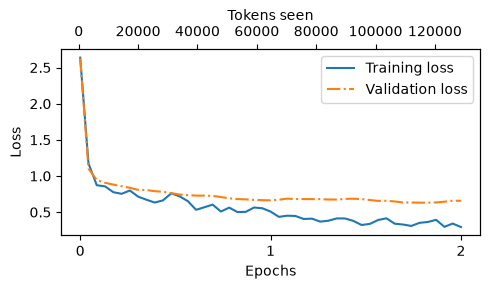

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
    epochs_seen, val_losses, linestyle="-.", label="Validation loss"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2 = ax1.twiny()
    ax2.plot(tokens_seen, train_losses, alpha=0)
    ax2.set_xlabel("Tokens seen")
    fig.tight_layout()
    plt.show()
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [35]:
"""
As can be seen from the training results the model quickly learns meaningful patterns and
representation fromt the data. But then as training progresses the loss decrease is slower and slower, 
suggesting that the model is converging to a stable solution and longer training will not increase
performance too much. 

But the loss only shows that the model is training effectively, we also need to look at some answers
to see the response quality and correctness.
"""

'\nAs can be seen from the training results the model quickly learns meaningful patterns and\nrepresentation fromt the data. But then as training progresses the loss decrease is slower and slower, \nsuggesting that the model is converging to a stable solution and longer training will not increase\nperformance too much. \n\nBut the loss only shows that the model is training effectively, we also need to look at some answers\nto see the response quality and correctness.\n'

### 7.7 Extracting and saving responses
Having fine-tuned the LLM we are ready to evaluate it on the held-out test set.

In [36]:
torch.manual_seed(123)

for entry in test_data[:3]:

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=30,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
)

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

    

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> The type of cloud associated with thunderstorms is a cumulus cloud.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.

Correct response:
>> Jane Austen.

Model response:
>> The author of 'Pride and Prej

As can be seen the model performs relatively well given the instructions, it correctly answers question 1 and 3 but not entirely correctly on question 2. However, model evaluation is not as straightforward as it is for classification models where we can just look at the classification accuracy. Instruction fine-tuned models (such as chatbots) are evaluated using other approaches, such as:
* Short-answer and multiple-choice benchmarks (e.g. measuring Massive Multitask Language Understanding, MMLU, which tests the models general knowledge)
* Human preference comparison to other LLMs (e.g. LMSYS chatbot arena)
* Automated conversational benchmarks where another more advanced LLM is used to evaluate the responses (e.g. AlpacaEval)

Human evaluation is useful but can be hard to achieve when dealing with a large number of examples (1100 in this case). Considering the scale we are gonna implement something similar to automated conversational benchmarks, which involves automatically evaluating the respones using another LLM.  

In [37]:
from tqdm import tqdm
for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
    input_text = format_input(entry)
    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )
    test_data[i]["model_response"] = response_text

with open("instruction-data-with-response.json", "w") as file:
    json.dump(test_data, file, indent=4)

100%|██████████| 110/110 [01:19<00:00,  1.38it/s]


In [38]:
print(test_data[1])

{'instruction': 'What type of cloud is typically associated with thunderstorms?', 'input': '', 'output': 'The type of cloud typically associated with thunderstorms is cumulonimbus.', 'model_response': 'The type of cloud associated with thunderstorms is a cumulus cloud.'}


In [39]:
# Save model so that we can reuse in the future
import re

file_name = f"{re.sub(r'[ ()]', '', CHOOSE_MODEL) }-sft.pth"     
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")

# Load
# model_state_dict = torch.load("gpt2-medium355M-sft.pth", map_location=device")
# model.load_state_dict(model_state_dict)

Model saved as gpt2-medium355M-sft.pth


### 7.8 Evaluating the fine-tuned LLM
Time to implement a automted evaluation for our fine-tuned model, wich we will do with an existing Llama 3 model run using Ollama

In [45]:
import psutil

def check_if_running(process_name):
    """Function that makes sure Ollama is running correctly"""
    running = False
    for proc in psutil.process_iter(["name"]):
        if process_name in proc.info["name"]:
            running = True
            break
    return running

ollama_running = check_if_running("ollama")
if not ollama_running:
    raise RuntimeError(
        "Ollama not running. Launch ollama before proceeding."
    )
print("ollama running: ", check_if_running("ollama"))

ollama running:  True


In [ ]:
# Load instruction and response data if python session was closed earlier
import json
from tqdm import tqdm
file_path = "instruction-data-with-response.json"
with open(file_path, "r") as file:
    test_data = json.load(file)
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )
    input_text = (
        f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    )
    return instruction_text + input_text

In [55]:
# An alternative to the ollama run command is to use REST APIs to interact with the model
import urllib.request

def query_model(prompt, model="llama3", url="http://localhost:11434/api/chat"):
    """Function that queries the model"""
    # Create data payload as dictionary
    data = {            
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {        # Settings for deterministic response
            "seed": 123,
            "temperature": 0,
            "num_ctx": 2048
        }
    }

    # Create a request object, setting method to POST and add necessary headers
    payload = json.dumps(data).encode("utf-8")   # Convert dict to JSON-formatted string
    request = urllib.request.Request(                      
        url,                                               
        data=payload,                                      
        method="POST"                                      
    )
    request.add_header("Content-Type", "application/json")

    # Send request and capture response
    response_data = ""
    with urllib.request.urlopen(request) as response:  
        while True:
            line = response.readline().decode("utf-8")
            if not line:
                break
            response_json = json.loads(line)
            response_data += response_json["message"]["content"]
    return response_data


In [56]:
model  = "llama3"
result = query_model("What do llamas eat?", model)
print(result)

Llamas are ruminant animals, which means they have a four-chambered stomach and are designed to eat and digest plant-based foods. In the wild, llamas are herbivores and their diet typically consists of:

1. Grasses: Llamas love to graze on various types of grasses, including tall grasses, short grasses, and grassy shrubs.
2. Leaves: They enjoy munching on leaves from trees and shrubs, including leaves from plants like willow, alder, and birch.
3. Fruits: Llamas will eat various fruits, such as apples, berries, and other soft fruits.
4. Bark: In the winter or when other food sources are scarce, llamas may eat the bark of trees, like willow or aspen.
5. Hay: In captivity, llamas are often fed hay, such as timothy hay or alfalfa hay, as a staple in their diet.
6. Grains: Some llamas may be fed grains like oats, corn, or barley, although these should not make up a large portion of their diet.
7. Minerals: Llamas need access to minerals like calcium, phosphorus, and salt to stay healthy.

I

In [ ]:
# Now that we can use the llama3 model through API's we can grade our GPT models answers
# Let's start with the first 3 entries in the dataset
for entry in test_data[:3]:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
    )
    print("\nDataset response:")
    print(">>", entry['output'])
    print("\nModel response:")
    print(">>", entry["model_response"])
    print("\nScore:")
    print(">>", query_model(prompt))
    print("\n-------------------------")


Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.

Score:
>> I'd score the model response "The car is as fast as a bullet." a 95 out of 100.

The response is very close to the original instruction, which asked to rewrite the sentence using a simile. The phrase "as fast as a bullet" is a common simile that effectively conveys the idea that the car is extremely fast. The only reason I wouldn't give it a perfect score is that "lightning" is a more common and iconic example of something that is extremely fast, which is why the original response "The car is as fast as lightning." is often considered the most idiomatic and natural-sounding simile in this context. However, "as fast as a bullet" is still a very good simile that effectively conveys the idea, and it's a common and natural-sounding phrase in its own right.

-------------------------

Dataset response:
>> The type of cloud typically associated with thunderstorms is cumulonim

In [59]:
# Since we want to look at scores we can prompt the model to only output a score

def generate_model_scores(json_data, json_key, model="llama3"):
    """Function that generates scores for all GPT-2 answers in the dataset"""
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
                f"Given the input `{format_input(entry)}` "
                f"and correct output `{entry['output']}`, "
                f"score the model response `{entry[json_key]}`"
                f" on a scale from 0 to 100, where 100 is the best score. "
                f"Respond with the integer number only."   # Only return the score
            )
        score = query_model(prompt, model)
        try:
            scores.append(int(score))
        except ValueError: # Skip non int responses
            print(f"Could not convert score: {score}")
            continue
    return scores

In [60]:
scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores) / len(scores):.2f}\n")

Scoring entries: 100%|██████████| 110/110 [04:34<00:00,  2.49s/it]

Number of scores: 110 of 110
Average score: 48.01

